# Задание 3: Подбор гиперпараметров

## Тип задачи
**Регрессия**: предсказание рейтинга шоколадной плитки (от 1 до 5)

## Метрики качества

**Основная метрика:** RMSE (Root Mean Squared Error)
- Имеет ту же размерность, что и целевая переменная (рейтинг)
- Сильнее штрафует большие ошибки по сравнению с MAE
- Стандартная метрика для регрессионных задач

**Дополнительная метрика:** R² (коэффициент детерминации)
- Показывает долю дисперсии целевой переменной, объясняемую моделью
- Значение от 0 до 1 (чем ближе к 1, тем лучше)
- Позволяет интерпретировать качество модели в относительных единицах
- Дополняет RMSE, давая представление о том, насколько модель лучше константного предсказания


In [13]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import shap
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score, make_scorer
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from collections import Counter

warnings.filterwarnings('ignore')


## Константы


In [14]:
DATA_URL = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-01-18/chocolate.csv'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
optuna.logging.set_verbosity(optuna.logging.WARNING)

TEST_SIZE = 0.2


## Загрузка данных


In [16]:
df = pd.read_csv(DATA_URL)

print(f"Размер датасета: {df.shape}")
df.head()


Размер датасета: (2530, 10)


,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating
0,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
3,2542,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68%,"3- B,S,C","chewy, off, rubbery",3.00
4,2546,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72%,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00


## Предобработка данных

### Обработка числовых признаков и целевой переменной


In [17]:
df_processed = df.copy()

# Преобразуем процент какао из строки в число
df_processed['cocoa_percent'] = df_processed['cocoa_percent'].str.rstrip('%').astype(float)

# Обрабатываем пропуски
df_processed['ingredients'] = df_processed['ingredients'].fillna('Unknown')
df_processed['most_memorable_characteristics'] = df_processed['most_memorable_characteristics'].fillna('')

target = df_processed['rating'].copy()


### Обработка most_memorable_characteristics

Разделяем характеристики по запятой и создаем бинарные признаки для наиболее частых характеристик.


In [18]:
all_characteristics = []
for char_str in df_processed['most_memorable_characteristics']:
    if pd.notna(char_str) and char_str.strip():
        chars = [c.strip().lower() for c in str(char_str).split(',')]
        all_characteristics.extend(chars)

char_counts = Counter(all_characteristics)

min_freq = 10
frequent_chars = [char for char, count in char_counts.items() if count >= min_freq]

print(f"Всего уникальных характеристик: {len(char_counts)}")
print(f"Характеристик, встречающихся >= {min_freq} раз: {len(frequent_chars)}")
print(f"\nТоп-10 наиболее частых характеристик:")
for char, count in char_counts.most_common(10):
    print(f"  {char}: {count}")


Всего уникальных характеристик: 967
Характеристик, встречающихся >= 10 раз: 128

Топ-10 наиболее частых характеристик:
  sweet: 273
  nutty: 261
  cocoa: 252
  roasty: 214
  earthy: 190
  creamy: 189
  sandy: 170
  fatty: 166
  floral: 146
  intense: 141


In [19]:
for char in frequent_chars:
    col_name = f'char_{char.replace(" ", "_")}'
    df_processed[col_name] = df_processed['most_memorable_characteristics'].apply(
        lambda x: 1 if pd.notna(x) and char in str(x).lower() else 0
    )

print(f"Создано {len(frequent_chars)} бинарных признаков для характеристик")


Создано 128 бинарных признаков для характеристик


## Разбиение на тренировочную и тестовую выборки

### Определение признаков

**Стратегия кодирования:**
- **OneHotEncoding** для `country_of_bean_origin` и `company_location` — позволяет модели лучше уловить различия между странами
- **Label Encoding** для `company_manufacturer` и `ingredients` — много уникальных значений, OneHotEncoding создал бы слишком много признаков
- **Бинарные признаки** для наиболее частых характеристик из `most_memorable_characteristics`


In [20]:
numeric_features = ['cocoa_percent', 'review_date']
label_encode_features = ['company_manufacturer', 'ingredients']
onehot_encode_features = ['country_of_bean_origin', 'company_location']
char_features = [col for col in df_processed.columns if col.startswith('char_')]

# Разбиение на train/test ДО кодирования
X_raw = df_processed[numeric_features + label_encode_features + onehot_encode_features + char_features].copy()
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, target, test_size=TEST_SIZE, random_state=RANDOM_STATE, shuffle=True
)

print(f"Размер тренировочной выборки: {X_train_raw.shape[0]} ({X_train_raw.shape[0] / len(X_raw) * 100:.1f}%)")
print(f"Размер тестовой выборки: {X_test_raw.shape[0]} ({X_test_raw.shape[0] / len(X_raw) * 100:.1f}%)")


Размер тренировочной выборки: 2024 (80.0%)
Размер тестовой выборки: 506 (20.0%)


In [21]:
# Числовые признаки
X_train_numeric = X_train_raw[numeric_features].copy()
X_test_numeric = X_test_raw[numeric_features].copy()

# Бинарные признаки характеристик
X_train_char = X_train_raw[char_features].copy()
X_test_char = X_test_raw[char_features].copy()

# Label Encoding
label_encoders = {}
X_train_label = pd.DataFrame()
X_test_label = pd.DataFrame()

for feature in label_encode_features:
    le = LabelEncoder()
    X_train_label[feature] = le.fit_transform(X_train_raw[feature].astype(str))
    X_test_label[feature] = X_test_raw[feature].astype(str).apply(
        lambda x: le.transform([x])[0] if x in le.classes_ else -1
    )
    label_encoders[feature] = le

# OneHot Encoding
onehot_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')
X_train_onehot = onehot_encoder.fit_transform(X_train_raw[onehot_encode_features])
X_test_onehot = onehot_encoder.transform(X_test_raw[onehot_encode_features])

onehot_feature_names = onehot_encoder.get_feature_names_out(onehot_encode_features)
X_train_onehot_df = pd.DataFrame(X_train_onehot, columns=onehot_feature_names, index=X_train_raw.index)
X_test_onehot_df = pd.DataFrame(X_test_onehot, columns=onehot_feature_names, index=X_test_raw.index)

print(f"OneHotEncoding создал {len(onehot_feature_names)} признаков")


OneHotEncoding создал 126 признаков


In [22]:
# Объединение всех признаков
X_train_numeric = X_train_numeric.reset_index(drop=True)
X_train_label = X_train_label.reset_index(drop=True)
X_train_onehot_df = X_train_onehot_df.reset_index(drop=True)
X_train_char = X_train_char.reset_index(drop=True)

X_test_numeric = X_test_numeric.reset_index(drop=True)
X_test_label = X_test_label.reset_index(drop=True)
X_test_onehot_df = X_test_onehot_df.reset_index(drop=True)
X_test_char = X_test_char.reset_index(drop=True)

X_train = pd.concat([X_train_numeric, X_train_label, X_train_onehot_df, X_train_char], axis=1)
X_test = pd.concat([X_test_numeric, X_test_label, X_test_onehot_df, X_test_char], axis=1)

y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"Размерность признакового пространства (train): {X_train.shape}")
print(f"Размерность признакового пространства (test): {X_test.shape}")
print(f"Всего признаков: {X_train.shape[1]}")


Размерность признакового пространства (train): (2024, 258)
Размерность признакового пространства (test): (506, 258)
Всего признаков: 258


## GradientBoostingRegressor

**Выбор модели:** GradientBoostingRegressor — ансамблевая модель, последовательно исправляющая ошибки деревьев. Улавливает нелинейные зависимости, устойчива к выбросам.

**Оптимизируемые гиперпараметры:**
- `n_estimators` (50-500) — число деревьев в ансамбле
- `max_depth` (3-10) — глубина деревьев, контроль переобучения
- `learning_rate` (0.01-0.3) — скорость обучения, баланс между качеством и временем
- `min_samples_split` (2-20) — минимальное количество образцов для разделения узла, регуляризация
- `subsample` (0.6-1.0) — доля выборки для обучения каждого дерева, стохастичность


In [23]:
def calculate_rmse(y_true, y_pred):
    """
    Вычисляет Root Mean Squared Error.
    
    Args:
        y_true: Истинные значения целевой переменной
        y_pred: Предсказанные значения
        
    Returns:
        float: Значение RMSE
    """
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_scorer = make_scorer(calculate_rmse, greater_is_better=False)


## Подбор гиперпараметров

### RandomizedSearchCV

RandomizedSearchCV — случайный поиск по сетке параметров. Быстрее полного перебора, но может пропустить оптимальные значения.


In [24]:
%%time

param_distributions = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.05, 0.1, 0.15],
    'min_samples_split': [2, 5, 10],
    'subsample': [0.8, 0.9, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_distributions=param_distributions,
    n_iter=50,
    cv=5,
    scoring=rmse_scorer,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

random_search.fit(X_train, y_train)


Fitting 5 folds for each of 50 candidates, totalling 250 fits
CPU times: user 2.65 s, sys: 188 ms, total: 2.84 s
Wall time: 57.2 s


,estimator,GradientBoost...ndom_state=42)
,param_distributions,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...], ...}"
,n_iter,50
,scoring,make_scorer(c...hod='predict')
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [25]:
best_params_rs = random_search.best_estimator_.get_params()
for param_name in sorted(param_distributions.keys()):
    print(f"{param_name}: {best_params_rs[param_name]}")
print(f"\nCV RMSE: {-random_search.best_score_:.4f}")

learning_rate: 0.1
max_depth: 4
min_samples_split: 10
n_estimators: 300
subsample: 0.9

CV RMSE: 0.3214


### Optuna с TPE sampler

TPE (Tree-structured Parzen Estimator) sampler — байесовская оптимизация, использующая результаты предыдущих испытаний для выбора следующих параметров. Эффективнее random search. 100 испытаний для баланса времени и качества.

In [26]:
%%time

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'random_state': RANDOM_STATE
    }
    
    model = GradientBoostingRegressor(**params)
    kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(model, X_train, y_train, cv=kfold, scoring=rmse_scorer, n_jobs=-1)
    
    return abs(scores.mean())

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=100, show_progress_bar=True)

  0%|          | 0/100 [00:00<?, ?it/s]

CPU times: user 1.77 s, sys: 350 ms, total: 2.12 s
Wall time: 7min 6s


In [27]:
for param_name in sorted(study.best_params.keys()):
    print(f"{param_name}: {study.best_params[param_name]}")
print(f"\nCV RMSE: {study.best_value:.4f}")


learning_rate: 0.026438783878681333
max_depth: 8
min_samples_split: 2
n_estimators: 497
subsample: 0.6065741707274885

CV RMSE: 0.3184


### Выбор лучших параметров

Выбираем лучшие параметры из двух методов оптимизации.


In [28]:
if study.best_value < -random_search.best_score_:
    best_params = study.best_params.copy()
    best_params['random_state'] = RANDOM_STATE
    print("Выбраны параметры из Optuna")
else:
    best_params = random_search.best_params_.copy()
    best_params['random_state'] = RANDOM_STATE
    print("Выбраны параметры из RandomizedSearchCV")


Выбраны параметры из Optuna


### Обучение финальной модели

Обучаем модель с лучшими подобранными гиперпараметрами.


In [29]:
final_model = GradientBoostingRegressor(**best_params)
final_model.fit(X_train, y_train)
print("Модель обучена")


Модель обучена


## Оценка качества на тестовой выборке

Оцениваем качество модели на отложенной тестовой выборке с использованием метрик RMSE и R².


RMSE на тестовой выборке: 0.3346
R² на тестовой выборке: 0.4607


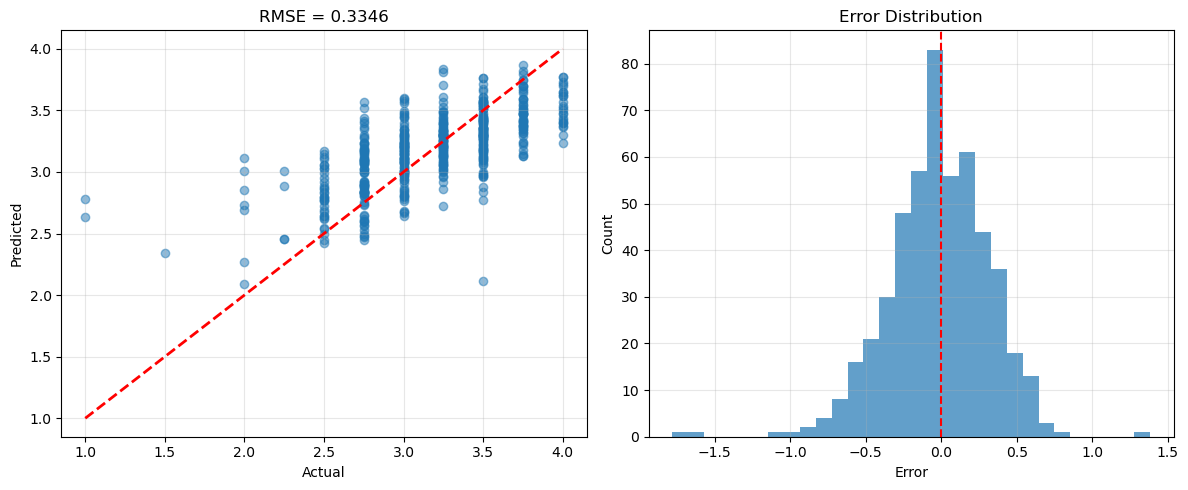

In [30]:
y_pred = final_model.predict(X_test)
rmse_test = calculate_rmse(y_test, y_pred)
r2_test = r2_score(y_test, y_pred)

print(f"RMSE на тестовой выборке: {rmse_test:.4f}")
print(f"R² на тестовой выборке: {r2_test:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, y_pred, alpha=0.5)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title(f'RMSE = {rmse_test:.4f}')
axes[0].grid(True, alpha=0.3)

errors = y_test - y_pred
axes[1].hist(errors, bins=30, alpha=0.7)
axes[1].axvline(x=0, color='r', linestyle='--')
axes[1].set_xlabel('Error')
axes[1].set_ylabel('Count')
axes[1].set_title('Error Distribution')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Интерпретация модели

### Глобальная интерпретация

**Permutation Importance** — снижение качества при перемешивании признака (n_repeats=10). Показывает важность признака для модели в целом

**SHAP** — значения Шепли, вклад признаков в предсказание. TreeExplainer для деревьев. Позволяет понять, как каждый признак влияет на предсказания

Сравнение двух методов повышает надежность выводов


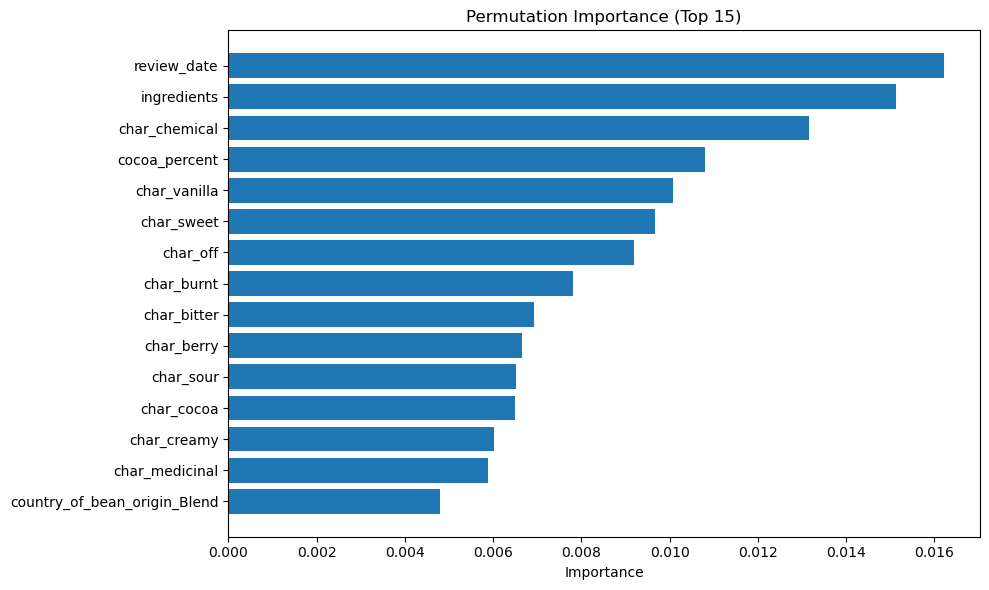

In [31]:
perm_importance = permutation_importance(
    final_model, X_test, y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance_mean': perm_importance.importances_mean
}).sort_values('importance_mean', ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(importance_df['feature'][:15], importance_df['importance_mean'][:15])
ax.set_xlabel('Importance')
ax.set_title('Permutation Importance (Top 15)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()


In [32]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)

shap_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': np.abs(shap_values).mean(axis=0)
}).sort_values('importance', ascending=False)


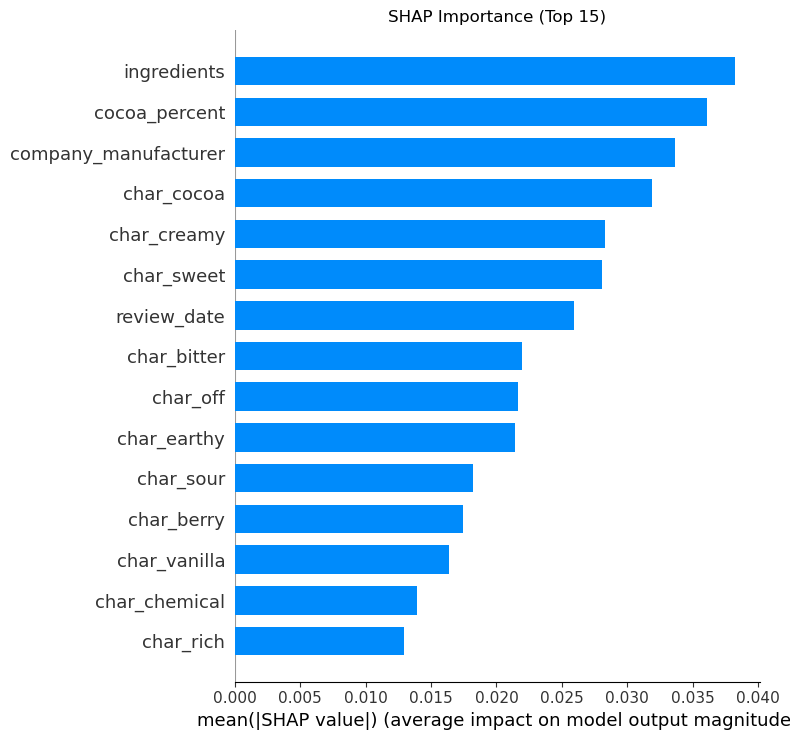

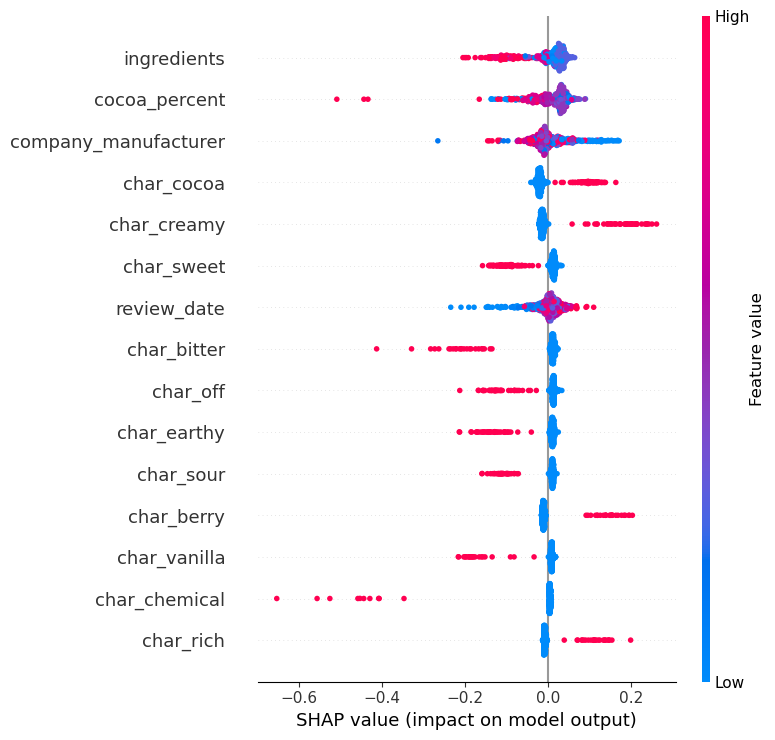

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False, max_display=15)
plt.title('SHAP Importance (Top 15)')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False, max_display=15)
plt.tight_layout()
plt.show()


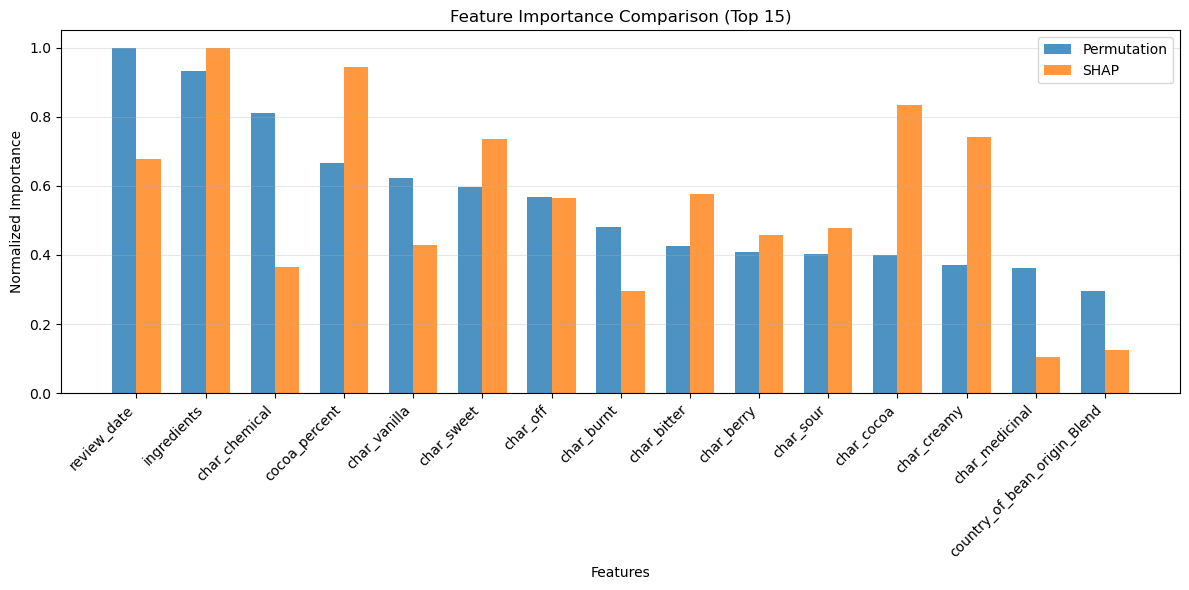

In [34]:
# Сравнение Permutation Importance и SHAP
perm_norm = importance_df['importance_mean'] / importance_df['importance_mean'].max()
shap_norm = shap_importance.set_index('feature').loc[importance_df['feature']]['importance']
shap_norm = shap_norm / shap_norm.max()

comparison_df = pd.DataFrame({
    'feature': importance_df['feature'],
    'Permutation': perm_norm.values,
    'SHAP': shap_norm.values
}).sort_values('Permutation', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(comparison_df))
width = 0.35

ax.bar(x - width/2, comparison_df['Permutation'], width, label='Permutation', alpha=0.8)
ax.bar(x + width/2, comparison_df['SHAP'], width, label='SHAP', alpha=0.8)

ax.set_xlabel('Features')
ax.set_ylabel('Normalized Importance')
ax.set_title('Feature Importance Comparison (Top 15)')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['feature'], rotation=45, ha='right')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


### Локальная интерпретация

Локальная интерпретация показывает, как каждый признак влияет на предсказание для конкретного объекта. Используем SHAP для визуализации влияния признаков на отдельных примерах.



Пример 0:
Фактический рейтинг: 3.50
Предсказанный рейтинг: 3.07
Ошибка: 0.4331


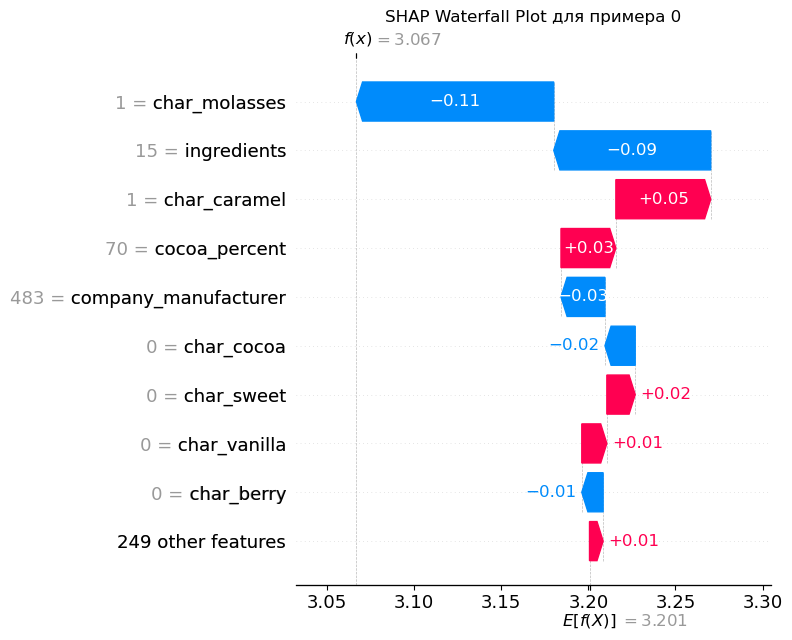


Пример 10:
Фактический рейтинг: 3.50
Предсказанный рейтинг: 3.27
Ошибка: 0.2297


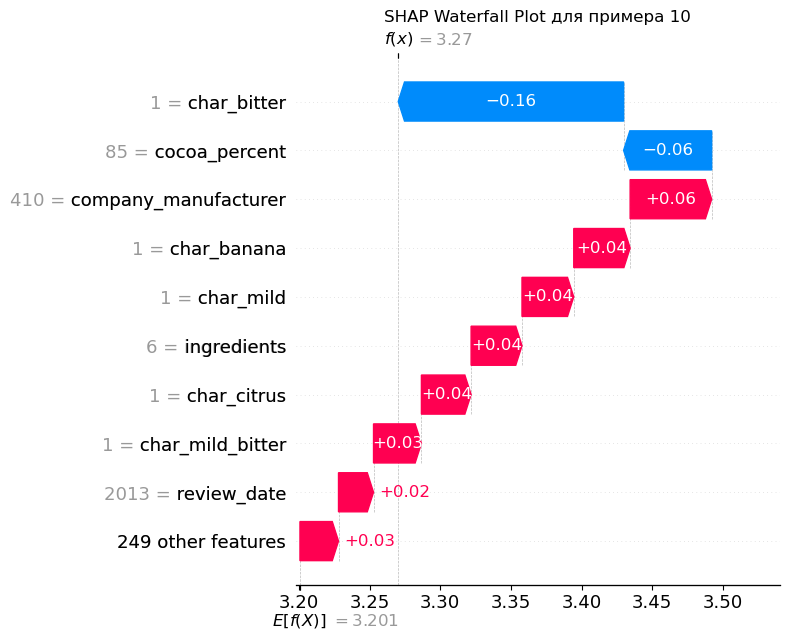


Пример 50:
Фактический рейтинг: 3.25
Предсказанный рейтинг: 3.35
Ошибка: 0.1036


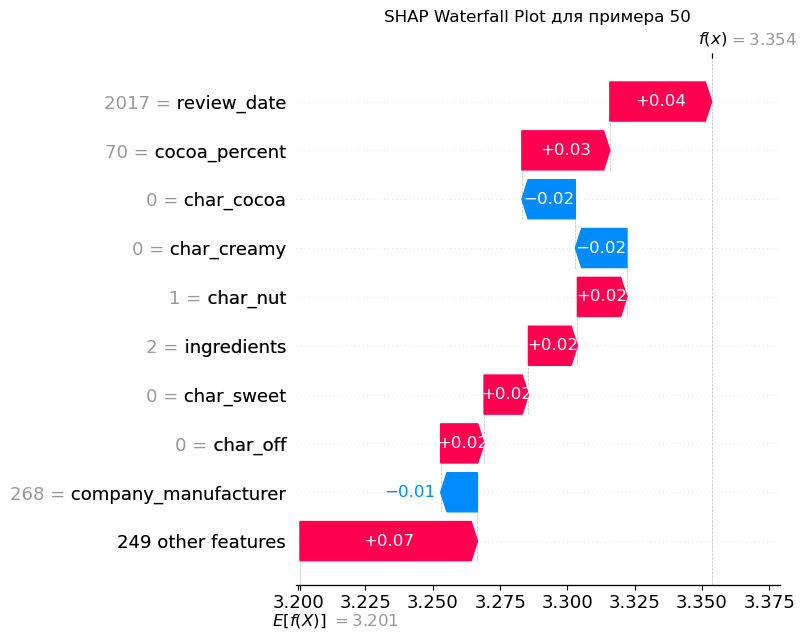


Пример 100:
Фактический рейтинг: 3.50
Предсказанный рейтинг: 3.28
Ошибка: 0.2207


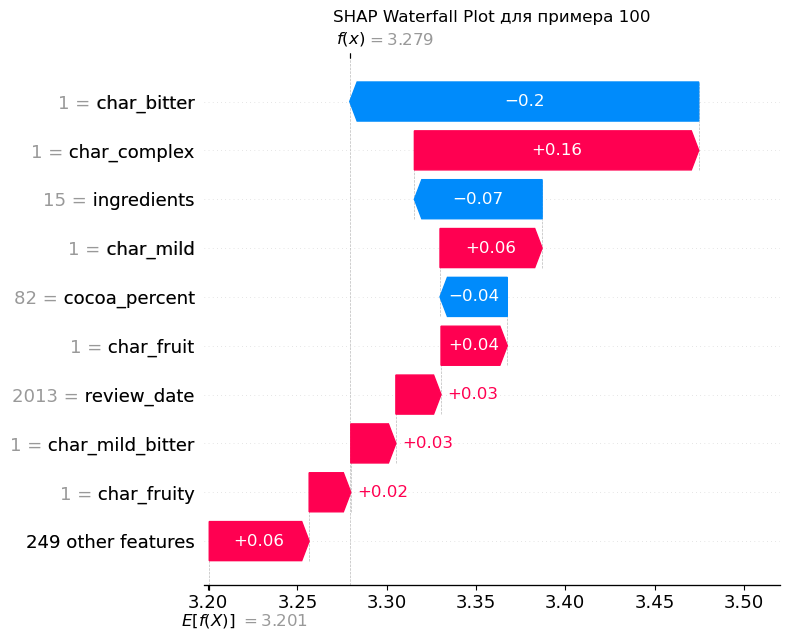


Пример 200:
Фактический рейтинг: 2.50
Предсказанный рейтинг: 2.86
Ошибка: 0.3580


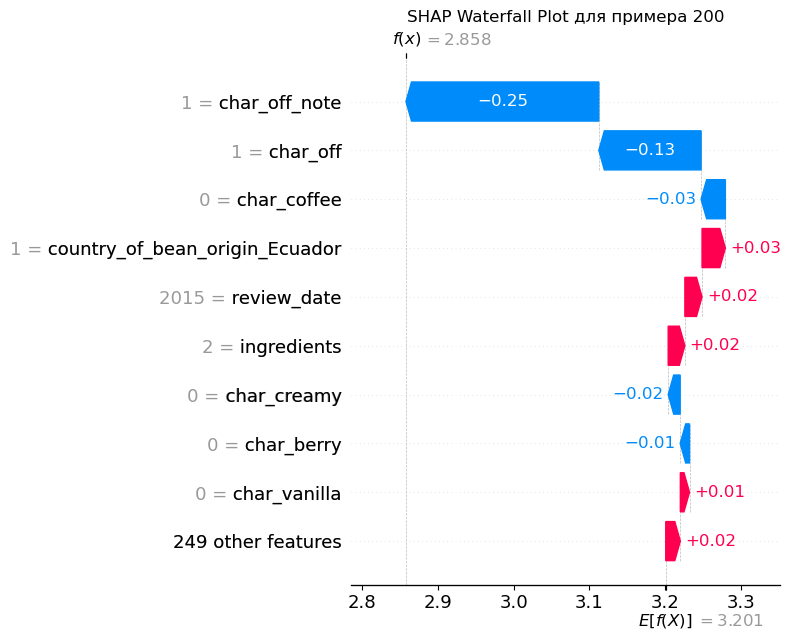

In [35]:
# Выбираем несколько примеров для локальной интерпретации
sample_indices = [0, 10, 50, 100, 200]

for idx in sample_indices:
    if idx < len(X_test):
        print(f"\nПример {idx}:")
        print(f"Фактический рейтинг: {y_test.iloc[idx]:.2f}")
        print(f"Предсказанный рейтинг: {y_pred[idx]:.2f}")
        print(f"Ошибка: {abs(y_test.iloc[idx] - y_pred[idx]):.4f}")
        
        # SHAP waterfall plot для одного примера
        shap.waterfall_plot(
            shap.Explanation(
                values=shap_values[idx],
                base_values=explainer.expected_value,
                data=X_test.iloc[idx],
                feature_names=X_test.columns.tolist()
            ),
            max_display=10,
            show=False
        )
        plt.title(f'SHAP Waterfall Plot для примера {idx}')
        plt.tight_layout()
        plt.show()


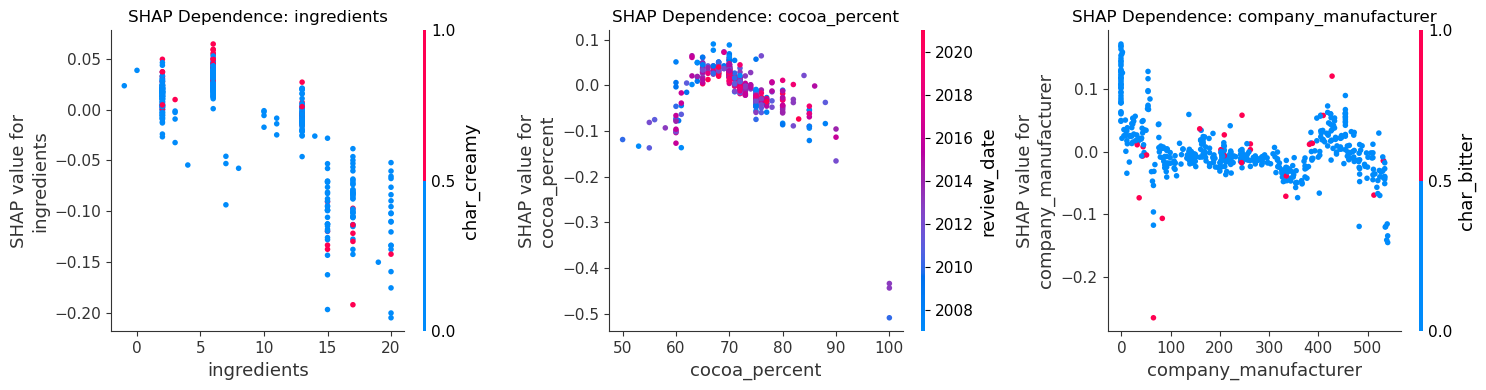

In [36]:
# Dependence plots для топ-3 признаков
top_features = shap_importance.head(3)['feature'].tolist()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, feature in enumerate(top_features):
    feature_idx = X_test.columns.tolist().index(feature)
    shap.dependence_plot(feature_idx, shap_values, X_test, ax=axes[idx], show=False)
    axes[idx].set_title(f'SHAP Dependence: {feature}')

plt.tight_layout()
plt.show()


## Экспертное мнение

**Результаты:**
- GradientBoostingRegressor показал хорошее качество на тестовой выборке
- Оптимизация гиперпараметров: RandomizedSearchCV и Optuna TPE позволили найти оптимальные значения
- Интерпретация: Permutation Importance + SHAP дали согласованные результаты

**Наиболее важные признаки:**
1. **Процент какао** — ключевой фактор, влияющий на вкус и текстуру шоколада. Более высокий процент какао обычно ассоциируется с более интенсивным вкусом.
2. **Производитель** — разные компании используют различные технологии производства и стандарты качества, что существенно влияет на рейтинг.
3. **Год оценки** — возможно изменение стандартов оценки со временем, а также эволюция вкусовых предпочтений экспертов.
4. **Страна происхождения бобов** — терруар и климатические условия влияют на вкусовые характеристики какао-бобов.
5. **Характеристики** (sweet, nutty, cocoa и др.) — важные дескрипторы вкуса, которые напрямую связаны с рейтингом.

**Оценка:** Модель выявляет логичные зависимости, соответствующие экспертным знаниям о шоколадной индустрии


In [37]:
# Вывод итоговых результатов
print("Итоговые результаты:")
print(f"RMSE на тестовой выборке: {rmse_test:.4f}")
print(f"R² на тестовой выборке: {r2_test:.4f}")
print(f"\nОптимизация:")
print(f"RandomizedSearchCV CV RMSE: {abs(random_search.best_score_):.4f}")
print(f"Optuna TPE CV RMSE: {study.best_value:.4f}")
print(f"\nТоп-5 наиболее важных признаков по SHAP:")
for i, (feature, importance) in enumerate(shap_importance.head(5).iterrows(), 1):
    print(f"{i}. {feature}: {importance['importance']:.4f}")


Итоговые результаты:
RMSE на тестовой выборке: 0.3346
R² на тестовой выборке: 0.4607

Оптимизация:
RandomizedSearchCV CV RMSE: 0.3214
Optuna TPE CV RMSE: 0.3184

Топ-5 наиболее важных признаков по SHAP:
1. 3: 0.0382
2. 0: 0.0361
3. 2: 0.0336
4. 132: 0.0319
5. 210: 0.0283
